# 01 · Stations: read and explore

*Turning raw weather-station reports into a clean hourly table.*

Somewhere on the edge of San Diego's airport runway stands a small white box on a pole that's about two metres off the ground. Inside it a thermometer is read automatically every few minutes and every hour the airport sends out a short coded message with the temperature, the humidity, the wind and whether it has rained. Thousands of these messages a day from tens of thousands of stations end up in one archive at NOAA, the US weather and ocean agency. This notebook follows those messages from the archive into a table that a model could train on.

We start with weather stations because they're the most direct sensor there is. A thermometer measures the air it sits in and there's almost no processing between the physical quantity and the number. That makes stations the clearest place to learn what a healthy sensor looks like which we need before we can recognise a sick one in later notebooks.

By the end of this notebook we'll have one row per station per hour for about 165 California stations over ten years (2015–2024) with temperature, dew point, wind and rain each carrying NOAA's own quality code. Along the way the data will surprise us several times. The stations aren't all the same kind of station, an "hourly" report isn't taken on the hour and NOAA's quality flags both catch and miss real errors.

## Why this step matters

Everything later in the project reads the table built here: matching stations to a weather model, planting faults, building checks and training a model. Two kinds of mistakes at this step would quietly spoil all of it.

The first is misreading the format. The archive stores temperature as text such as `+0217,1` where the number is in *tenths* of a degree Celsius (21.7 °C) and the digit after the comma is a quality code. The value `+9999` means "missing". A parser that forgets either rule produces data that looks plausible and is wrong, like a 999.9 °C afternoon.

The second is subtler. A station's file doesn't contain one row per hour. Several kinds of report share each hour measured at different minutes and turning them into one value per hour needs a rule that someone has to choose and write down. That rule decides which minute of the hour your "hourly" temperature describes.

**What to look for below:** how complete the records are, how much temperature depends on place and how often NOAA's own quality codes object. That last number tells us how much work our own checks will have to do.

> **In ML terms.** This notebook is the data-loading and schema-validation stage of a training pipeline. Raw records arrive in a vendor format with sentinel values, mixed precision and duplicate events per time bucket. The output is a typed and deduplicated table with one row per entity and time step.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


## Step 1 · The station list

The archive is NOAA's **Integrated Surface Database (ISD)**. It holds hourly and sub-hourly reports from land stations, ships and buoys worldwide collected since the 1900s. A free copy lives on Amazon Web Services (AWS) in the bucket `noaa-global-hourly-pds` that's readable without an account.

NOAA also publishes a list of every station it has ever received data from in `isd-history.csv`. Each station is named by two numbers glued together. The first six digits are a **USAF** number from a scheme the US Air Force started. The last five are a **WBAN** number from the old Weather Bureau, Army and Navy scheme. San Diego's airport is `722900` + `23188` = `72290023188`. Stations that only have one of the two numbers get the other filled with 9s.

We keep California stations whose active dates cover the whole of 2015–2024. Active dates only say that a station reported *something* in those years. How complete the record really is we measure ourselves in step 5.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wxlab import stations as st

YEARS = range(2015, 2025)
RAW_DIR = os.path.join(DATA_DIR, "raw", "isd")         # raw CSVs, never modified
STD_DIR = os.path.join(DATA_DIR, "standardized", "isd")                           # one Parquet file per station-year

history = st.load_station_history(os.path.join(DATA_DIR, "meta"))
ca = st.california_stations(history, YEARS[0], YEARS[-1])
FEATURED = {"coast": "72290023188", "desert": "72286893138", "mountain": "72389403181"}  # San Diego, Palm Springs, Mammoth
ids = ca["station_id"].tolist()
print(f"{len(history):,} stations worldwide; {len(ca)} in California cover {YEARS[0]}-{YEARS[-1]}; this run uses {len(ids)}")
ca[ca.station_id.isin(FEATURED.values())][["station_id", "name", "lat", "lon", "elevation_m"]]

29,661 stations worldwide; 165 in California cover 2015-2024; this run uses 165


,station_id,name,lat,lon,elevation_m
15,72286893138,PALM SPRINGS INTL AIRPORT,33.822,-116.504,124.7
26,72290023188,SAN DIEGO INTERNATIONAL AIRPORT,32.734,-117.183,4.6
59,72389403181,MAMMOTH YOSEMITE AIRPORT,37.633,-118.850,2172.6


## Step 2 · One raw file exactly as it arrives

Before building anything look at the raw material. Below are the first rows of San Diego's 2024 file decoded into the columns we use. `obs_time` is when the report was made in **UTC** (Coordinated Universal Time). That's the time zone weather data always uses and California is 7 or 8 hours behind it.

In [3]:
import s3fs
fs = s3fs.S3FileSystem(anon=True)  # public bucket, no credentials
raw_sd = st.parse_raw(fs.open("noaa-global-hourly-pds/2024/72290023188.csv"))
raw_sd[["obs_time", "report_type", "air_temperature", "dew_point_temperature", "wind_speed", "precipitation_1h"]].head(8)

,obs_time,report_type,air_temperature,dew_point_temperature,wind_speed,precipitation_1h
0,2024-01-01 00:00:00+00:00,FM-12,16.1,11.7,0.0,NaN
1,2024-01-01 00:17:00+00:00,FM-15,15.6,6.1,1.5,0.0
2,2024-01-01 00:51:00+00:00,FM-15,14.4,11.7,2.1,NaN
3,2024-01-01 01:51:00+00:00,FM-15,17.3,12.0,0.0,0.0
4,2024-01-01 02:51:00+00:00,FM-15,13.3,11.7,0.0,0.0
5,2024-01-01 03:00:00+00:00,FM-12,13.3,11.7,0.0,NaN
6,2024-01-01 03:51:00+00:00,FM-15,12.8,11.1,0.0,NaN
7,2024-01-01 04:51:00+00:00,FM-15,12.2,11.7,1.5,NaN


Look at the first hour of 2024. There's a report at 00:00 another at 00:17 and another at 00:51. They're different kinds of message named by codes from the World Meteorological Organization:

- **FM-15, the METAR.** The routine report airports produce for pilots. It's issued a few minutes *before* each hour so that it's ready on the hour. At San Diego that's minute 51.
- **FM-16, the SPECI.** A special report sent whenever the weather changes enough to matter for flying, like fog rolling in, rain starting or the wind jumping. It can appear at any minute.
- **FM-12, the SYNOP.** The international report weather services exchange with each other every three or six hours timed exactly on the hour.
- **SOD and SOM.** Daily and monthly summaries that aren't observations at all.

So "the 1 a.m. temperature" in this file could mean the SYNOP at 00:00 or the METAR measured at 00:51 or a SPECI from 00:17. The next cell counts how often hours have more than one report and at which minute each kind of report usually arrives.

In [4]:
obs = raw_sd[~raw_sd.report_type.isin(st.SUMMARY_TYPES)]
print("report types in this file:", raw_sd.report_type.value_counts().to_dict())
print("reports per hour:", obs.groupby(obs.obs_time.dt.round("h")).size().value_counts().sort_index().to_dict())
for rt in ["FM-15", "FM-16", "FM-12"]:
    print(f"usual minutes for {rt}:", obs[obs.report_type == rt].obs_time.dt.minute.value_counts().head(3).to_dict())

report types in this file: {'FM-15': 8767, 'FM-12': 2768, 'FM-16': 2419, 'SOD': 357, 'SOM': 12, 'SY-MT': 9}
reports per hour: {1: 4844, 2: 3038, 3: 633, 4: 162, 5: 49, 6: 24, 7: 13, 8: 2}
usual minutes for FM-15: {51: 8755, 17: 1, 4: 1}
usual minutes for FM-16: {47: 95, 49: 87, 28: 57}
usual minutes for FM-12: {0: 2768}


**The rule.** A training table needs exactly one value per station per hour chosen by a rule we can write down and audit:

1. Drop the summaries.
2. Give each report to the *nearest* UTC hour. So 00:51 belongs to 01:00 and 01:17 also belongs to 01:00. Each hour owns a window of ±30 minutes.
3. Within an hour prefer a report that has a temperature, then FM-15 over FM-16 over FM-12, then the one closest to the hour.

The table keeps the chosen report's original time and type and the number of competing reports so any choice can be checked later. The raw files are cached untouched and the hourly table is a separate layer derived from them.

> **In ML terms.** Several events land in each time bucket and you need one label per bucket. That's deduplication with a precedence rule, the same problem as choosing between a payment's "authorized", "captured" and "settled" events. The rule has to be deterministic so that rerunning the pipeline gives identical output.

In [5]:
hourly_sd = st.to_hourly(raw_sd)
hourly_sd[["time", "air_temperature", "tmp_quality", "report_type", "obs_time", "n_reports"]].head(5)

,time,air_temperature,tmp_quality,report_type,obs_time,n_reports
0,2024-01-01 00:00:00+00:00,15.6,5,FM-15,2024-01-01 00:17:00+00:00,2
1,2024-01-01 01:00:00+00:00,14.4,1,FM-15,2024-01-01 00:51:00+00:00,1
2,2024-01-01 02:00:00+00:00,17.3,5,FM-15,2024-01-01 01:51:00+00:00,1
3,2024-01-01 03:00:00+00:00,13.3,5,FM-15,2024-01-01 02:51:00+00:00,2
4,2024-01-01 04:00:00+00:00,12.8,1,FM-15,2024-01-01 03:51:00+00:00,1


## Step 3 · What each field means

The ISD format document is NOAA's specification for these files and it defines every field. These are the four we use and how each is written:

| Field | Raw text | Meaning | Missing |
|---|---|---|---|
| `TMP` air temperature | `+0144,5` | 14.4 °C (tenths of a degree), quality code 5 | `+9999` |
| `DEW` dew point | `+0089,5` | 8.9 °C, quality code 5 | `+9999` |
| `WND` wind | `220,5,N,0026,5` | from 220° (south-west), quality 5, type N (normal), 2.6 m/s, quality 5 | direction `999`, speed `9999` |
| `AA1` precipitation | `01,0003,9,5` | over the last 1 hour, 0.3 mm, condition 9, quality 5 | depth `9999` |

**Dew point** is the temperature the air would have to cool to for its water vapour to start condensing into dew. Dry desert air has a dew point far below the air temperature and foggy coastal air has a dew point almost equal to it. Dew point can never be higher than the air temperature which gives us a free physical check later.

**Wind** is reported as the direction it blows *from* in degrees (0 is north and 90 is east) plus a speed. Calm air is reported with type `C` and speed zero.

**Precipitation** is reported as an amount collected over a period. Routine reports carry the last hour. Synoptic reports carry six-hour totals and daily summaries carry 24-hour totals. Mixing those would count the same rain several times so we keep only one-hour amounts.

Every value carries a one-character **quality code** set by NOAA's own automatic checks. These are the ones that matter most:

| Code | Meaning |
|---|---|
| `1`, `5` | Passed all checks (`1` for data NOAA processed itself, `5` for data received from other centres) |
| `2`, `6` | Suspect |
| `3`, `7` | Erroneous |
| `9` | Missing |
| `C` | Value came from a station that reports whole degrees Celsius. Flagged by the checks but accepted |
| `A`, `P` | Suspect but accepted; suspect but not checked |

Our standardized table uses CF-style names which is the community standard for naming weather and climate variables: `air_temperature` and `dew_point_temperature` in °C, `wind_speed` in m/s and `precipitation_1h` in mm. NOAA's quality code stays beside each value.

## Step 4 · Build every station

`st.build` downloads every station-year in parallel threads. Downloading is mostly waiting on the network so threads are enough. It caches the raw CSV and writes one Parquet file per station-year. Each station-year is a unit of work that's **idempotent**, meaning rerunning it gives the same file. Finished units are skipped so a crash or a rerun is always safe. Files are written under a temporary name and renamed when complete so a half-written file can never be mistaken for a finished one.

The first run downloads about 10 GB of raw CSV which takes roughly 30 minutes. The standardized output is under 300 MB.

In [6]:
status = st.build(ids, YEARS, RAW_DIR, STD_DIR)
print(f"{status.available.sum()} of {len(status)} station-years exist on AWS; {status.error.notna().sum()} download errors")
hourly = st.load_standardized(STD_DIR, station_ids=ids, years=YEARS)
networks = st.station_networks(hourly)
print(f"{len(hourly):,} station-hours from {hourly.station_id.nunique()} stations, "
      f"{hourly.dropna(subset=['air_temperature']).station_id.nunique()} of which report temperature")
print("stations by network:", networks.value_counts().to_dict())
print("chosen report types:", hourly.report_type.value_counts().to_dict())
usual_minute = hourly[hourly.report_type == "FM-15"].groupby("station_id").obs_time.agg(lambda t: t.dt.minute.mode().iat[0])
print("airports by the usual minute of their routine report:", usual_minute.value_counts().to_dict())

1614 of 1650 station-years exist on AWS; 0 download errors


13,048,970 station-hours from 165 stations, 160 of which report temperature
stations by network: {'airport': 135, 'coastal': 23, 'climate reference': 7}
chosen report types: {'FM-15': 10777317, 'FM-13': 1634516, 'CRN05': 603700, 'FM-12': 14286, 'SHEF': 10575, 'FM-16': 5535, 'SY-MT': 3041}


airports by the usual minute of their routine report: {53: 41, 55: 34, 56: 21, 58: 7, 52: 6, 51: 6, 47: 5, 54: 5, 0: 4, 59: 3, 45: 2, 50: 1}


The first surprise is that these aren't all the same kind of station. NOAA's station list doesn't say what network a station belongs to but the report types give it away. There are three:

- **Airport stations** are most of them and they send the routine METAR. In the US these are automated systems called **ASOS** at larger airports (run by the weather service and the aviation agency) and **AWOS** at smaller ones.
- **Climate reference stations** belong to the **US Climate Reference Network (USCRN)**, a small research network built specifically to measure climate change. Each site has three separate thermometers so a failing one can be spotted and it's placed away from buildings and asphalt. ISD stores their readings as 5-minute data with report type `CRN05`.
- **Coastal stations** sit on piers, bays and platforms. They're water-level stations that also measure the weather and they report in the marine synoptic format `FM-13`.

This matters later. Climate reference stations are the closest thing we have to trusted ground truth. Coastal stations measure air over water which a weather model treats differently from air over land.

The last line holds the second surprise. San Diego issues its routine report at minute 51 but that's not a rule. Each airport has its own minute (most often 53 or 55) and a few report on the hour. Our 14:00 value is really "the routine report closest to 14:00" measured anywhere from about 15 minutes before the hour to on the hour depending on the station.

## Step 5 · Where the stations are

California packs very different climates into a small area. There's a cool ocean-moderated coast, a hot dry interior valley, deserts below sea level and mountains above 2,000 m. The map colours each station by elevation and marks its network. Elevation matters a lot for temperature because air cools by roughly 6.5 °C for every kilometre you climb. That's the **lapse rate** and notebook 03 corrects for it.

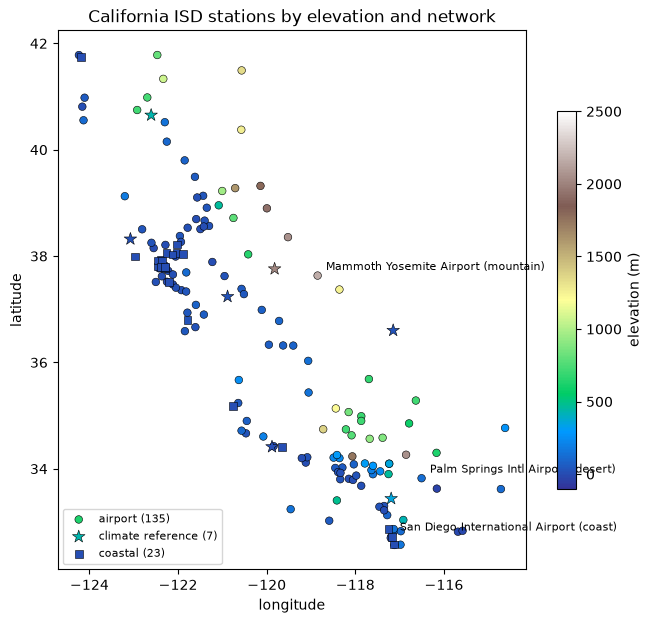

In [7]:
meta = (hourly.groupby("station_id")[["latitude", "longitude", "elevation_m"]].median()
        .join(ca.set_index("station_id")["name"]).join(networks))
fig, ax = plt.subplots(figsize=(8, 7))
markers = {"airport": "o", "climate reference": "*", "coastal": "s", "other": "^"}
for net, m in markers.items():
    g = meta[meta.network == net]
    if g.empty:
        continue
    sc = ax.scatter(g.longitude, g.latitude, c=g.elevation_m, cmap="terrain", vmin=-100, vmax=2500,
                    s=90 if m == "*" else 30, marker=m, edgecolor="k", linewidth=0.4, label=f"{net} ({len(g)})")
for label, sid in FEATURED.items():
    r = meta.loc[sid]
    ax.annotate(f"{r['name'].title()} ({label})", (r.longitude, r.latitude), fontsize=8, xytext=(6, 4), textcoords="offset points")
plt.colorbar(sc, label="elevation (m)", shrink=0.7)
ax.legend(loc="lower left", fontsize=8); ax.set_aspect(1.2)
ax.set(xlabel="longitude", ylabel="latitude", title="California ISD stations by elevation and network")
plt.show()

Stations cluster along the coast and the Central Valley where people and airports are. The deserts and the Sierra Nevada are thinly covered. This is what "sparse sensors" means in practice. They're accurate at a few points and absent in between and the gaps aren't random. The places that are hardest to predict are the ones with the fewest measurements.

## Step 6 · How complete is each record?

**Completeness** is the fraction of a year's hours that have a temperature. It's the first and cheapest quality metric and it's never evenly spread.

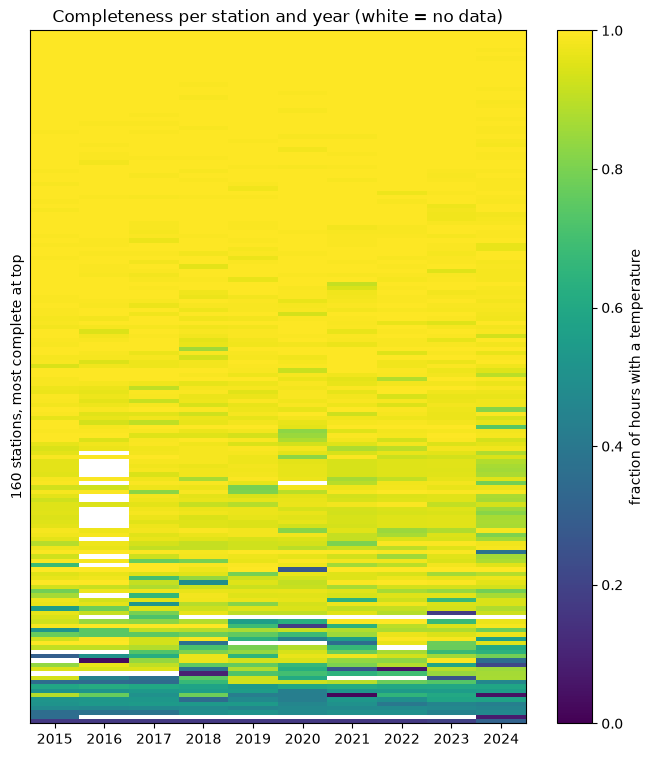

station-years >= 90% complete: 84%;  below 50%: 4%
stations >= 90% complete in every year 2021-2024: 101


In [8]:
comp = st.completeness(hourly).reindex(columns=list(YEARS))
order = comp.mean(axis=1).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(comp.loc[order].values, aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
ax.set_xticks(range(len(YEARS)), list(YEARS)); ax.set_yticks([])
ax.set_ylabel(f"{len(order)} stations, most complete at top")
plt.colorbar(im, label="fraction of hours with a temperature"); ax.set_title("Completeness per station and year (white = no data)")
plt.show()
c = comp.stack()
print(f"station-years >= 90% complete: {(c >= 0.9).mean():.0%};  below 50%: {(c < 0.5).mean():.0%}")
print(f"stations >= 90% complete in every year 2021-2024: {(comp[[2021, 2022, 2023, 2024]].fillna(0) >= 0.9).all(axis=1).sum()}")

The top of the heatmap is a solid block where most stations report almost every hour of every year. Lower down there are holes: whole missing years, years a third complete and stations that start late or stop early. Some gaps are outages and some are stations that changed identifiers. The later notebooks use 2021–2024 and the last line above counts how many stations are nearly complete over that window.

## Step 7 · Three climates

Below are the daily mean temperatures for 2023 at a coastal, a desert and a mountain station.

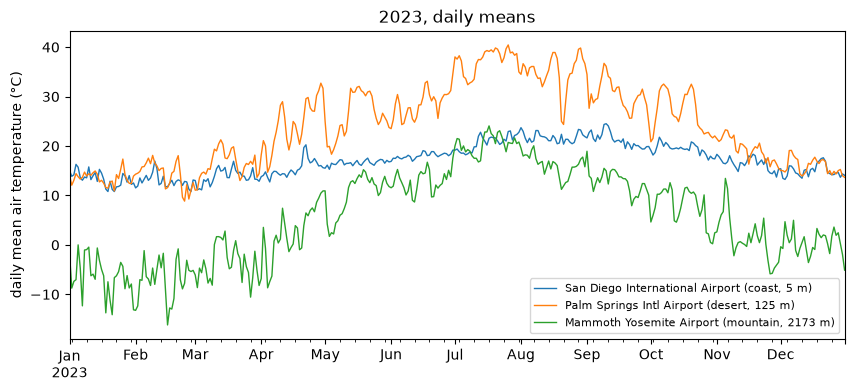

In [9]:
def series(sid, col="air_temperature"):
    return hourly[hourly.station_id == sid].set_index("time")[col].sort_index()

def label(sid, kind):
    return f"{meta.loc[sid, 'name'].title()} ({kind}, {meta.loc[sid, 'elevation_m']:.0f} m)"

fig, ax = plt.subplots(figsize=(10, 4))
for kind, sid in FEATURED.items():
    series(sid)["2023"].resample("D").mean().plot(ax=ax, lw=1, label=label(sid, kind))
ax.set(ylabel="daily mean air temperature (°C)", xlabel="", title="2023, daily means"); ax.legend(fontsize=8)
plt.show()

The coast barely moves through the year because the ocean stores heat and releases it slowly. Palm Springs is in the desert at almost the same latitude and swings from mild winters to summer daily *means* in the mid-30s. Mammoth sits at about 2,170 m and averages about 17 °C below Palm Springs. The lapse rate alone predicts about 13 °C for a 2 km height difference. The rest is the desert itself. It's a low basin whose ground heats the air above it far more than free air at the same height would be heated. One model has to learn all three regimes and any check that asks "is this value plausible?" has to know which regime it's in.

## Step 8 · The daily and seasonal cycles

The **diurnal cycle** is the daily rise from a minimum just before dawn to a maximum in mid-afternoon. To see it we convert UTC to California local time and average by local hour. The **seasonal cycle** is the same idea by month.

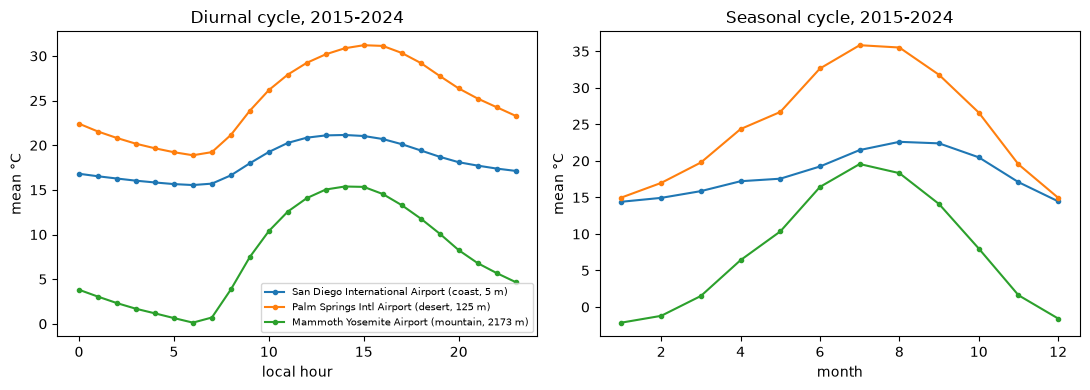

average daily range (warmest minus coolest hour), °C: {'coast': np.float64(5.6), 'desert': np.float64(12.3), 'mountain': np.float64(15.2)}


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ranges = {}
for kind, sid in FEATURED.items():
    s = series(sid)
    local = s.tz_convert("America/Los_Angeles")
    by_hour = local.groupby(local.index.hour).mean()
    ranges[kind] = round(by_hour.max() - by_hour.min(), 1)
    by_hour.plot(ax=axes[0], marker=".", label=label(sid, kind))
    s.groupby(s.index.month).mean().plot(ax=axes[1], marker=".", label=label(sid, kind))
axes[0].set(xlabel="local hour", ylabel="mean °C", title="Diurnal cycle, 2015-2024")
axes[1].set(xlabel="month", ylabel="mean °C", title="Seasonal cycle, 2015-2024")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
print("average daily range (warmest minus coolest hour), °C:", ranges)

The coast's daily range is small. The desert's and the mountain's are large because dry air and clear skies let the ground heat up fast by day and lose heat fast at night.

That has two consequences for later notebooks. First, a one-hour timestamp error costs almost nothing at the coast but several degrees in the desert at sunrise. So a **time-offset fault** will be easiest to see at stations with a big daily swing. Second, if this table had been stored in local time the daylight-saving switch would have shifted every value by an hour twice a year. Storing UTC avoids that and converting to local time only for plots is a deliberate and visible step.

> **In ML terms.** The diurnal and seasonal cycles are strong and predictable periodic signals. A model gets most of its accuracy from them for free so the errors that matter are departures from the cycle. Notebook 05 removes the expected cycle (the **climatology**) and looks at what's left, the **anomaly**.

## Step 9 · How precise is a reading?

The table stores temperatures with one decimal but that doesn't mean the sensor measured to a tenth of a degree. The next cell checks for each network how often a value is a whole number of degrees Fahrenheit, a whole number of degrees Celsius or neither.

In [11]:
t = hourly[["station_id", "air_temperature"]].dropna().join(networks, on="station_id")
f = t.air_temperature * 9 / 5 + 32
t["resolution"] = np.select(
    [np.isclose(t.air_temperature, t.air_temperature.round(), atol=0.01), np.isclose(f, f.round(), atol=0.06)],
    ["whole °C", "whole °F"], "tenths")
t.groupby("network")["resolution"].value_counts(normalize=True).unstack().round(2)

resolution,tenths,whole °C,whole °F
network,,,
airport,0.21,0.33,0.46
climate reference,0.78,0.10,0.12
coastal,0.78,0.10,0.12


Here's a quick sanity rule for reading this table. Values recorded in tenths of a degree land on a whole °C about 10% of the time and near a whole °F about 12% of the time by chance alone. That's exactly what the climate reference and coastal networks show so they really do record tenths.

Airports are different. Most of their values sit on whole degrees. US airport sensors report in Fahrenheit and the archive converts to Celsius. So 60, 61 and 62 °F become 15.6, 16.1 and 16.7 °C, which are steps of about 0.56 °C. Smaller airports often report only whole degrees Celsius and that's what quality code `C` marks. Only about a fifth of airport values carry real tenths.

This matters for two later checks. A "stuck sensor" check looks for values that don't change and at whole-degree resolution a calm night can legitimately repeat the same value for hours. And a planted drift of 0.1 °C per year is smaller than one step of the airport sensors.

## Step 10 · Two previews of quality questions

**Dew point above temperature.** It's physically impossible so any case is an error. How many are there?

**Missing data in storms.** Sensors and communications tend to fail in bad weather which is exactly when a weather model most needs data. Here a storm hour is an hour with wind of at least 10 m/s or at least 2.5 mm of rain in the hour. We compare how often temperature is missing in storm hours and in other hours. This only covers hours in which the station reported *something*. Hours with no report at all can't be classified from the station's own data and notebook 03 uses the weather model to fill that gap.

In [12]:
both = hourly.dropna(subset=["air_temperature", "dew_point_temperature"])
print(f"dew point above air temperature: {(both.dew_point_temperature > both.air_temperature + 0.05).sum()} of {len(both):,} hours")
storm = (hourly.wind_speed >= 10) | (hourly.precipitation_1h >= 2.5)
miss = hourly.air_temperature.isna()
print(f"storm hours: {storm.sum():,};  temperature missing in storm hours {miss[storm].mean():.2%}, in other hours {miss[~storm].mean():.2%}")

dew point above air temperature: 0 of 10,831,637 hours
storm hours: 219,378;  temperature missing in storm hours 3.60%, in other hours 3.11%


No hour has a dew point above the temperature. That's good news about the data and it also means this check will only catch faults we plant in notebook 04, since a sensor that drifts warm or cold breaks the relationship between the two. Missing temperatures are somewhat more common in storm hours than in other hours. The effect is small in this data but the direction is the one that hurts a model because the gaps aren't random.

## Step 11 · How often do NOAA's own quality codes object?

In [13]:
LABELS = {"1": "passed", "5": "passed", "2": "suspect", "6": "suspect", "3": "erroneous", "7": "erroneous",
          "9": "missing", "A": "suspect, accepted", "C": "whole °C, accepted", "P": "suspect, not checked"}
q = hourly.loc[hourly.air_temperature.notna(), "tmp_quality"]
table = q.value_counts().rename("hours").to_frame()
table["meaning"] = table.index.map(LABELS)
table["share"] = (table.hours / table.hours.sum()).map("{:.3%}".format)
table

,hours,meaning,share
tmp_quality,,,
5,7950277,passed,62.884%
1,2434973,passed,19.260%
C,2200934,"whole °C, accepted",17.409%
7,38477,erroneous,0.304%
6,15133,suspect,0.120%
2,1760,suspect,0.014%
A,1053,"suspect, accepted",0.008%
P,73,"suspect, not checked",0.001%


Most values pass but "erroneous" and "suspect" aren't rare everywhere. They're concentrated in a few stations. The next cell lists the station-years where NOAA marked more than half of the temperatures as erroneous and the most extreme temperatures that NOAA marked as *passed*.

In [14]:
h = hourly[hourly.air_temperature.notna()].assign(year=lambda d: d.time.dt.year)
bad = h.tmp_quality.isin(["3", "7"]).groupby([h.station_id, h.year]).mean()
bad = bad[bad > 0.5].rename("share erroneous").reset_index()
bad["name"] = bad.station_id.map(meta["name"])
print(bad.to_string(index=False))
passed = h[h.tmp_quality.isin(["1", "5"])]
extreme = passed.nlargest(3, "air_temperature")[["station_id", "time", "air_temperature", "tmp_quality"]]
extreme["name"] = extreme.station_id.map(meta["name"])
extreme

 station_id  year  share erroneous                     name
72026723224  2015         0.926008 AUBURN MUNICIPAL AIRPORT
74509023244  2020         0.862620 MOFFETT FEDERAL AIRFIELD
74509023244  2021         0.971123 MOFFETT FEDERAL AIRFIELD
74509023244  2022         0.931268 MOFFETT FEDERAL AIRFIELD
74509023244  2023         0.911028 MOFFETT FEDERAL AIRFIELD
74509023244  2024         0.847105 MOFFETT FEDERAL AIRFIELD


,station_id,time,air_temperature,tmp_quality,name
5165223,72026723224,2019-09-03 01:00:00+00:00,58.0,5,AUBURN MUNICIPAL AIRPORT
11771863,72026723224,2024-11-08 12:00:00+00:00,57.0,5,AUBURN MUNICIPAL AIRPORT
5165042,72026723224,2019-08-26 11:00:00+00:00,56.0,5,AUBURN MUNICIPAL AIRPORT


Two different stories sit in these tables.

NOAA's checks clearly do catch some systematic problems because whole station-years are marked erroneous. Moffett Federal Airfield for example has most of its temperatures marked erroneous from 2020 onward. Something changed there and notebook 05 will look at what.

But the checks also pass values that can't be right. The warmest "passed" readings include values in the mid-50s °C at stations and times where that's implausible, like at night in November. That's close to the highest temperature ever recorded on Earth (56.7 °C in Death Valley in 1913). NOAA's quality code is evidence and not truth. That's why our own checks compare each station with independent sources rather than only judging values one at a time.

> **In ML terms.** Vendor-provided labels about data quality are noisy labels themselves. Treat them as one feature of trustworthiness, measure how often they agree with independent evidence and never use them as ground truth without checking.

## What surprised me

**The stations are three different networks.** The station list looks uniform but it mixes airport stations, research-grade climate reference stations and coastal stations on piers and platforms. They differ in instruments, report formats and precision and even in what "the air temperature" means (over land or over water). A pipeline that treats them alike throws away information.

**"Hourly" data isn't one row per hour and isn't on the hour.** Routine airport reports, special reports and synoptic reports share each hour. The routine report is measured several minutes before the hour at a minute that differs between airports. The hourly table needs a written rule for which report wins and it keeps the original time so the rule can be audited.

**The data is less precise than it looks.** Most airport temperatures are whole degrees Fahrenheit converted to Celsius so the "tenths" are an artefact of unit conversion.

**NOAA's quality flags both catch and miss.** They mark whole years of a station as erroneous and they also pass physically implausible values. Flags are evidence to weigh and not answers.

## Check yourself

<details><summary>A report at 13:52 UTC and another at 14:09 UTC both carry a temperature. Which hour does each belong to and which one becomes the 14:00 value if both are FM-15?</summary>
Both round to 14:00. Both are FM-15 so the one closer to the hour wins. 14:09 is 9 minutes away and 13:52 is 8 minutes away so 13:52 wins.
</details>

<details><summary>Why does the table keep NOAA's quality code instead of dropping values NOAA marked erroneous?</summary>
Because flags are evidence and not truth. NOAA marks some good data and passes some bad data. Keeping every value with its flag lets later checks weigh the evidence and lets users choose their own strictness. Deleting can't be undone.
</details>

<details><summary>Why would a 1-hour timestamp error be easy to detect at Palm Springs and hard at San Diego?</summary>
Palm Springs has a large daily cycle so shifting it by an hour moves the morning warm-up and evening cool-down by several degrees. San Diego's daily cycle is small so the same shift changes values very little.
</details>

<details><summary>Why are coastal stations a problem when comparing with a weather model?</summary>
They measure air over or next to water. A model grid cell 3 km across may be mostly land or mostly water so the station and the model can disagree for reasons that have nothing to do with a faulty sensor.
</details>

New terms from this notebook are collected in [`docs/glossary.md`](../docs/glossary.md).